In [61]:
%pip install yfinance

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [62]:
import yfinance as yf

In [63]:
import warnings
warnings.filterwarnings('ignore')

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [65]:
TICKER='MSFT'
START_DATE='2020-01-01'
END_DATE = '2024-01-01'

In [66]:
df_test= yf.download(TICKER, start=START_DATE,end=END_DATE).reset_index()

[*********************100%***********************]  1 of 1 completed


In [67]:
print(f"Number of columns downloaded:{len(df_test.columns)}")

Number of columns downloaded:6


In [68]:
print(f"Column Names:{list(df_test.columns)}")

Column Names:[('Date', ''), ('Close', 'MSFT'), ('High', 'MSFT'), ('Low', 'MSFT'), ('Open', 'MSFT'), ('Volume', 'MSFT')]


In [69]:
TICKER='MSFT'
START_DATE='2020-01-01'
END_DATE = '2024-01-01'

In [70]:
print(f"Downloading historical data for {TICKER}..")

In [71]:
df=yf.download(TICKER, start=START_DATE,end=END_DATE).reset_index()

[*********************100%***********************]  1 of 1 completed


In [72]:
df.columns = ['_'.join(col).strip()for col in df.columns.values]

In [73]:
df.rename(columns={'Date_':'Date','Close_MSFT':'close','High_MSFT': 'High','Low_MSFT': 'LOW','Open_MSFT': 'Open', 'Volume_MSFT': 'Volume'},inplace=True)

In [74]:
df['Adj close']=df['close']

In [75]:
df=df.sort_values('Date').reset_index(drop=True)

In [76]:
print(f"Data sample for {TICKER} (Fixed):")
print(df.head())

Data sample for MSFT (Fixed):
        Date       close        High         LOW        Open    Volume  \
0 2020-01-02  151.544250  151.648036  149.383652  149.808222  22622100   
1 2020-01-03  149.657303  150.912154  149.128947  149.374266  21116200   
2 2020-01-06  150.044128  150.110180  147.666515  148.204315  20813700   
3 2020-01-07  148.676025  150.647928  148.430722  150.317713  21634100   
4 2020-01-08  151.044205  151.714093  149.025125  149.949746  27746500   

    Adj close  
0  151.544250  
1  149.657303  
2  150.044128  
3  148.676025  
4  151.044205  


In [77]:
df.set_index('Date', inplace=True)

In [78]:
df['Daily Return'] = df['Adj close'].pct_change()

In [79]:
dr = df['Daily Return'].dropna()

In [80]:
print("\nDaily Return stats:")
print(dr.describe())


Daily Return stats:
count    1005.000000
mean        0.001095
std         0.020546
min        -0.147390
25%        -0.009447
50%         0.000978
75%         0.012024
max         0.142169
Name: Daily Return, dtype: float64


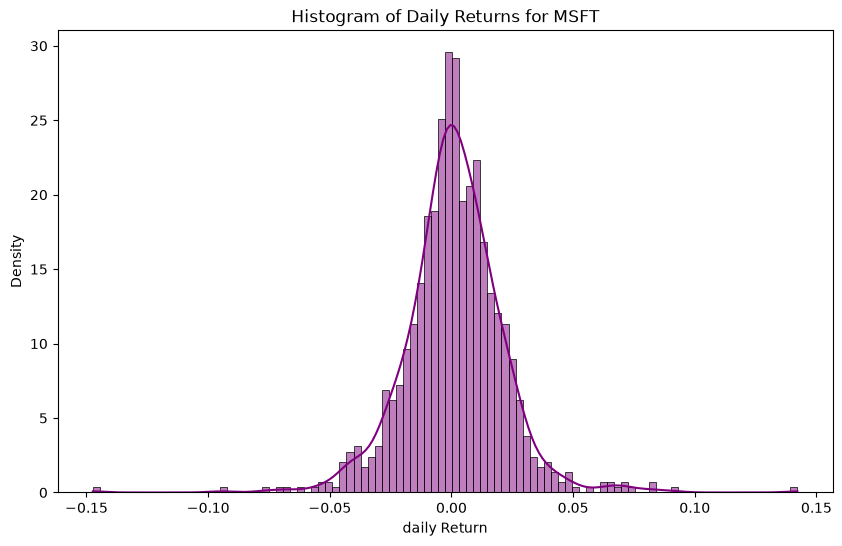

In [81]:
plt.figure(figsize=(10,6))
sns.histplot(dr, bins=100, kde=True, color='purple',stat='density')
plt.title(f'Histogram of Daily Returns for {TICKER}')
plt.xlabel('daily Return')
plt.ylabel('Density')
plt.show()

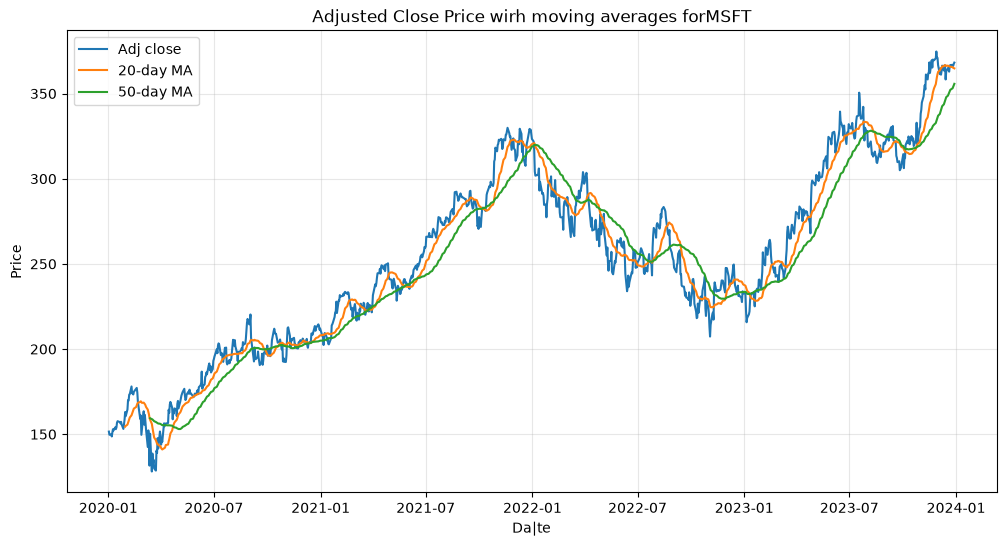

In [83]:
plt.figure(figsize=(12,6))
plt.plot(df['Adj close'],label='Adj close')
plt.plot(df['Adj close'].rolling(20).mean(), label='20-day MA')
plt.plot(df['Adj close'].rolling(50).mean(), label='50-day MA')
plt.title(f'Adjusted Close Price wirh moving averages for{TICKER}')
plt.xlabel('Da|te')
plt.ylabel('Price')
plt.legend()
plt.grid(alpha=0.3)
plt.show()